# Training

学習条件を上流から確認し、事前チェック後にsmoke testまたは本学習を明示的に実行し、保存済み結果を可視化します。

このNotebookはYAMLを書き換えません。設定を変更した場合は先頭から再実行してください。


## 1. 使用する設定

通常はこのパスだけ確認します。別実験のYAMLを使う場合のみ変更してください。


In [1]:
from pathlib import Path
import csv, subprocess, sys
import matplotlib.pyplot as plt
import yaml
from IPython.display import Image, Markdown, display

def find_project_root(start):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "configs").is_dir() and (candidate / "performance").is_dir():
            return candidate
    raise FileNotFoundError("FNOV2リポジトリ内からNotebookを開いてください。")

def resolve(value, config_path):
    path = Path(value)
    return path.resolve() if path.is_absolute() else (config_path.parent / path).resolve()

def status(ok, label, detail=""):
    mark = "✅" if ok else "❌"
    print(f"{mark} {label}" + (f": {detail}" if detail else ""))
    return ok

ROOT = find_project_root(Path.cwd())
print("project:", ROOT)
#################################
EXPERIMENT_ID = "ex009_baseline"
#################################
print("experiment:", EXPERIMENT_ID)
TRAIN_YAML = ROOT / "configs/train.yaml"
train_cfg = yaml.safe_load(TRAIN_YAML.read_text(encoding="utf-8"))
model_path = resolve(train_cfg["training"]["model_config"], TRAIN_YAML)
model_cfg = yaml.safe_load(model_path.read_text(encoding="utf-8"))
loader_path = resolve(model_cfg["model"]["dataloader_config"], model_path)
loader_cfg = yaml.safe_load(loader_path.read_text(encoding="utf-8"))
dataset_path = resolve(loader_cfg["dataset_config"], loader_path)
dataset_cfg = yaml.safe_load(dataset_path.read_text(encoding="utf-8"))
output_dir = resolve(train_cfg["output"]["directory"], TRAIN_YAML)


project: /workspace/FNOV2
experiment: ex009_baseline


## 2. 設定の可視化


In [2]:
summary = {
    "train config": str(TRAIN_YAML),
    "model": model_cfg["model"]["name"],
    "modes / hidden / layers": [model_cfg["model"]["n_modes"], model_cfg["model"]["hidden_channels"], model_cfg["model"]["n_layers"]],
    "train Re": loader_cfg["split"]["train_re"],
    "validation Re": loader_cfg["split"]["val_re"],
    "batch size": loader_cfg["loader"]["batch_size"],
    "epochs / device": [train_cfg["training"]["epochs"], train_cfg["training"]["device"]],
    "optimizer / learning rate": [train_cfg["optimizer"]["type"], train_cfg["optimizer"]["learning_rate"]],
    "scheduler": train_cfg["scheduler"],
    "loss": train_cfg["loss"],
    "normalization": dataset_cfg["normalization"],
    "W&B": train_cfg.get("wandb", {}),
    "output": str(output_dir),
}
display(Markdown("### 重要設定"))
print(yaml.safe_dump(summary, allow_unicode=True, sort_keys=False))
display(Markdown("### train.yaml 全文"))
print(TRAIN_YAML.read_text(encoding="utf-8"))


### 重要設定

train config: /workspace/FNOV2/configs/train.yaml
model: FNO
modes / hidden / layers:
- - 48
  - 48
- 256
- 4
train Re:
- 10
- 20
- 30
- 40
- 60
- 70
- 80
- 90
- 110
- 120
- 130
- 140
- 160
- 170
- 180
- 190
- 210
- 220
- 230
- 240
- 250
validation Re:
- 50
- 100
- 150
- 200
batch size: 8
epochs / device:
- 300
- cuda
optimizer / learning rate:
- adam
- 0.0005
scheduler:
  type: cosine_annealing
  min_learning_rate: 1.0e-06
loss:
  type: mse
  valid_region_only: false
normalization:
  statistics_file: normalization_stats.yaml
  mask:
    type: none
  Re:
    type: scale
    scale: 250.0
  x:
    type: scale
    scale: 1.6
  y:
    type: scale
    scale: 0.41
  fields:
    type: standardize
    statistics_source: train
    valid_region_only: true
W&B:
  enabled: true
  project: fnov2-cylinder-wake
  entity: null
  name: null
  group: baseline
  job_type: train
  tags:
  - fno
  - baseline
  - one-step
  notes: Baseline FNO one-step prediction
  mode: online
  save_code: true
  log_inter

### train.yaml 全文

training:
  model_config: model.yaml
  epochs: 300
  seed: 42
  device: cuda
  deterministic: false
  gradient_clip_norm: null
  resume_checkpoint: null

optimizer:
  type: adam
  learning_rate: 0.0005
  weight_decay: 0.0

scheduler:
  type: cosine_annealing
  min_learning_rate: 0.000001

loss:
  # baselineはstandardized u/v/pに対する全格子点MSE。
  type: mse
  valid_region_only: false

output:
  #####################################
  directory: ../outputs/training/ex009
  #####################################
  checkpoint_interval: 10

wandb:
  enabled: true
  project: fnov2-cylinder-wake
  entity: null
  name: null
  group: baseline
  job_type: train
  tags:
    - fno
    - baseline
    - one-step
  notes: Baseline FNO one-step prediction

  # online: クラウドへ同期、offline: ローカル保存のみ、disabled: W&B無効。
  mode: online
  save_code: true
  log_interval_steps: 10

  # 同じW&B runを再開する場合にrun_idを設定する。
  run_id: null
  resume: allow

  watch:
    enabled: false
    log: all
    log_freq: 100

  log_best_checkp

## 3. 実行前チェック


In [3]:
data_dir = resolve(dataset_cfg["dataset"]["data_dir"], dataset_path)
pair_files = sorted(data_dir.glob(dataset_cfg["dataset"]["file_pattern"]))
train_re = set(map(float, loader_cfg["split"]["train_re"]))
val_re = set(map(float, loader_cfg["split"]["val_re"]))
checks = [
    status(TRAIN_YAML.is_file(), "train config", TRAIN_YAML),
    status(model_path.is_file(), "model config", model_path),
    status(loader_path.is_file(), "dataloader config", loader_path),
    status(dataset_path.is_file(), "dataset config", dataset_path),
    status(data_dir.is_dir(), "training data directory", data_dir),
    status(bool(pair_files), "pair files", f"{len(pair_files)} files"),
    status(train_re.isdisjoint(val_re), "train/validation Re separation"),
    status(output_dir.name in ({"ex009"} if EXPERIMENT_ID == "ex009_baseline" else {EXPERIMENT_ID}), "experiment training output", output_dir),
]
resume = train_cfg["training"].get("resume_checkpoint")
if resume:
    checks.append(status(resolve(resume, TRAIN_YAML).is_file(), "resume checkpoint", resolve(resume, TRAIN_YAML)))
PRECHECK_OK = all(checks)
print("\n実行可能" if PRECHECK_OK else "\n設定またはデータを修正してから実行してください。")


✅ train config: /workspace/FNOV2/configs/train.yaml
✅ model config: /workspace/FNOV2/configs/model.yaml
✅ dataloader config: /workspace/FNOV2/configs/dataloader.yaml
✅ dataset config: /workspace/FNOV2/configs/dataset.yaml
✅ training data directory: /workspace/FNOV2/data/processed/pairs
✅ pair files: 30 files
✅ train/validation Re separation
✅ experiment training output: /workspace/FNOV2/outputs/training/ex009

実行可能


## 4. Smoke test

1 train batchと1 validation batchだけを実行し、結果ファイルは保存しません。


In [4]:
RUN_SMOKE_TEST = True
if RUN_SMOKE_TEST:
    if not PRECHECK_OK: raise RuntimeError("事前チェックが失敗しています。")
    subprocess.run([sys.executable, str(ROOT/"src/train.py"), "--config", str(TRAIN_YAML), "--smoke-test"], cwd=ROOT, check=True)
else:
    print("未実行。確認後にRUN_SMOKE_TEST=Trueへ変更してください。")


parameters      : 315,134,467
=== Training Setup ===
device          : cuda
epochs          : 1
train samples   : 2100
val samples     : 400
optimizer       : adam
learning rate   : 0.0005
loss            : mse (valid_region_only=False)
output directory: /workspace/FNOV2/outputs/training/ex009
smoke test      : 1 train batch + 1 validation batch
wandb           : disabled
epoch 0001 | train=1.112408e+00 | val=5.915021e-01 | train_rel_l2=1.004110e+00 | val_rel_l2=9.991787e-01 | lr=5.000e-04 | best_val=5.915021e-01 | 1.3s
best validation loss: 5.915021e-01


## 5. 本学習

既存の出力先を使用します。output.directoryとresume_checkpointを必ず確認してから有効化してください。


In [5]:
RUN_TRAINING = True
if RUN_TRAINING:
    if not PRECHECK_OK: raise RuntimeError("事前チェックが失敗しています。")
    subprocess.run([sys.executable, str(ROOT/"src/train.py"), "--config", str(TRAIN_YAML)], cwd=ROOT, check=True)
else:
    print("未実行。確認後にRUN_TRAINING=Trueへ変更してください。")


wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: sotaron9012 (str-kit) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run 2wdvm04m
wandb: Tracking run with wandb version 0.28.2
wandb: Run data is saved locally in /workspace/FNOV2/outputs/training/ex009/wandb/run-20261109_144748-2wdvm04m
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run glad-wind-89
wandb: ⭐️ View project at https://wandb.ai/str-kit/fnov2-cylinder-wake
wandb: 🚀 View run at https://wandb.ai/str-kit/fnov2-cylinder-wake/runs/2wdvm04m


parameters      : 315,134,467
=== Training Setup ===
device          : cuda
epochs          : 300
train samples   : 2100
val samples     : 400
optimizer       : adam
learning rate   : 0.0005
loss            : mse (valid_region_only=False)
output directory: /workspace/FNOV2/outputs/training/ex009
wandb           : https://wandb.ai/str-kit/fnov2-cylinder-wake/runs/2wdvm04m
epoch 0001 | train=5.804228e-02 | val=5.920703e-04 | train_rel_l2=2.423548e-01 | val_rel_l2=3.002427e-02 | lr=5.000e-04 | best_val=5.920703e-04 | 143.2s
epoch 0002 | train=4.986744e-04 | val=4.369406e-04 | train_rel_l2=2.246404e-02 | val_rel_l2=2.579271e-02 | lr=5.000e-04 | best_val=4.369406e-04 | 158.6s
epoch 0003 | train=2.319480e-04 | val=1.200813e-04 | train_rel_l2=1.532056e-02 | val_rel_l2=1.352146e-02 | lr=4.999e-04 | best_val=1.200813e-04 | 158.0s
epoch 0004 | train=1.019301e-03 | val=1.015110e-04 | train_rel_l2=3.211667e-02 | val_rel_l2=1.243204e-02 | lr=4.999e-04 | best_val=1.015110e-04 | 155.1s
epoch 0005 | t

wandb: uploading artifact fnov2-fno-baseline; updating run metadata
wandb: uploading artifact fnov2-fno-baseline
wandb: uploading artifact fnov2-fno-baseline; uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: uploading artifact fnov2-fno-baseline
wandb: uploading artifact fnov2-fno-baseline; uploading history steps 8159-8159, summary, console lines 311-311
wandb: uploading artifact fnov2-fno-baseline
wandb: uploading artifact fnov2-fno-baseline; uploading data
wandb: uploading artifact fnov2-fno-baseline
wandb: uploading data
wandb: 
wandb: Run history:
wandb:                             epoch ▁▁▁▂▂▃▃▃▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇████
wandb:                     epoch_seconds ▇▇▄▇▇▆▂▆▆█▇▇▄▇▇▇▆▇▆▇▇▁▄▃▂██▆▃▆▄▇▆▄▂▆▃▅▃▁
wandb:          gpu_memory/allocated_gib ▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:      gpu_memory/allocated_percent ▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:     gpu_memory/peak_allocated_gib ▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁

## 6. 保存済み学習結果


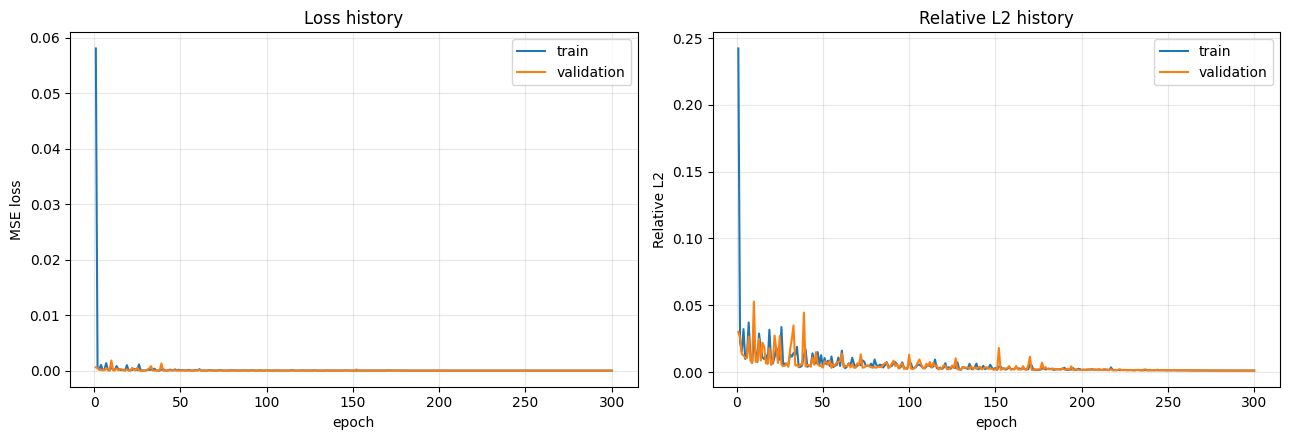

best validation Relative L2: 0.0011281158074487045 at epoch 290
✅ best.pt: /workspace/FNOV2/outputs/training/ex009/best.pt
✅ last.pt: /workspace/FNOV2/outputs/training/ex009/last.pt
✅ history.csv: /workspace/FNOV2/outputs/training/ex009/history.csv
✅ history.json: /workspace/FNOV2/outputs/training/ex009/history.json


In [6]:
history_path = output_dir / "history.csv"
if not history_path.exists():
    print("学習履歴がありません:", history_path)
else:
    with history_path.open(encoding="utf-8", newline="") as f: rows=list(csv.DictReader(f))
    epoch=[int(r["epoch"]) for r in rows]
    fig,axes=plt.subplots(1,2,figsize=(13,4.5))
    axes[0].plot(epoch,[float(r["train_loss"]) for r in rows],label="train")
    axes[0].plot(epoch,[float(r["val_loss"]) for r in rows],label="validation")
    axes[1].plot(epoch,[float(r["train_relative_l2"]) for r in rows],label="train")
    axes[1].plot(epoch,[float(r["val_relative_l2"]) for r in rows],label="validation")
    axes[0].set(xlabel="epoch",ylabel="MSE loss",title="Loss history")
    axes[1].set(xlabel="epoch",ylabel="Relative L2",title="Relative L2 history")
    for ax in axes: ax.grid(alpha=.3); ax.legend()
    plt.tight_layout(); plt.show()
    best=min(rows,key=lambda r:float(r["val_relative_l2"]))
    print("best validation Relative L2:",best["val_relative_l2"],"at epoch",best["epoch"])
for name in ("best.pt","last.pt","history.csv","history.json"):
    status((output_dir/name).exists(),name,output_dir/name)
